<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">ANALYSE DE LA PERFORMANCE ÉCONOMIQUE ET OPTIMISATION DE L'ENTREPRISE</h2>
</div>


# OBJECTIF DE CE NOTEBOOK

Ce notebook a pour objectif d'analyser la performance économique et commerciale d'une entreprise de jardinage en Île-de-France, à partir d'un jeu de données d'environ 900 interventions.

### SOMMAIRE

1. **Exploration et nettoyage des données** : contrôle de la qualité et préparation du jeu de données.
2. **Analyse descriptive** : calcul des KPI et indicateurs économiques globaux.
3. **Performance et rentabilité** : analyse du chiffre d'affaires, des coûts et des marges par segment.
4. **Analyse de la saisonnalité** : identification des périodes de forte et faible activité.
5. **Inférence statistique** : tests d'hypothèses, corrélations et intervalles de confiance.
6. **Optimisation économique** : simulations de scénarios et identification de leviers d'amélioration.
7. **Conclusion et recommandations** : synthèse des résultats et propositions opérationnelles.



<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies, chargement des fichiers et configuration visuelle</h2>
</div>

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import bootstrap
from scipy.stats import kruskal
from scipy.stats import mannwhitneyu
from scipy.stats import spearmanr
from itertools import combinations
from statsmodels.stats.multitest import multipletests

In [2]:
# 1. Palette personnalisée pour les catégories
CATEG_PALETTE = {0: '#e9d4cf',   1: '#a06f8d',  2: '#2d223a' }

# 2. Palette générale 
GENERAL_PALETTE = ['#8c5db8','#b08cbf','#a68da8','#b9a7b0','#ded6d1']

In [3]:
# 3. Thème global Seaborn 
sns.set_theme(
    style="whitegrid",
    rc={
        "figure.figsize": (10, 5.5),
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.labelsize": 12,
        "axes.labelweight": "bold",
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "font.family": "DejaVu Sans",
        "axes.edgecolor": "#333333",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
    }
)

# 4. Palette par défaut
sns.set_palette(GENERAL_PALETTE)

In [4]:
BASE_DIR = Path.cwd()  # dossier actuel du notebook

df_data = pd.read_csv(BASE_DIR / "data" / "dataset_elagueur.csv", sep=";")

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire des fichiers</h2>
</div>


In [5]:
df_data.head()

,date,activite,prestation,client,commune,statut,canal_acquisition,CA_HT_eur,commission_eur,heures_travaillees,couts_eur,marge_eur
0,2025-10-16,Conception,Apport d'affaires,CL-071,Igny,Facture,Site web,139.34,139.34,2.17,95.76,43.58
1,2025-08-27,Entretien SAP,Taille de haie,CL-024,Verrières-le-Buisson,Facture,Site web,131.64,0.00,1.67,87.50,44.14
2,2025-07-12,Entretien SAP,Entretien jardin,CL-151,Palaiseau,Facture,Bouche-a-oreille,201.01,0.00,2.54,91.40,109.61
3,2024-08-08,Creation jardin,Semis gazon,CL-027,Orsay,Facture,Client recurrent,984.84,0.00,7.01,245.67,739.17
4,2026-01-17,Entretien SAP,Taille de haie,CL-250,Montlhéry,Facture,Bouche-a-oreille,261.74,0.00,6.89,245.31,16.43


In [6]:
print(f" Nombre de ligne dans le dataframe : {len(df_data)}")

 Nombre de ligne dans le dataframe : 910


In [7]:
df_data.isna().sum()

date                  0
activite              0
prestation            0
client                0
commune               0
statut                0
canal_acquisition     0
CA_HT_eur             0
commission_eur        0
heures_travaillees    0
couts_eur             0
marge_eur             0
dtype: int64

In [8]:
doublons_stricts = df_data.duplicated()
df_data[doublons_stricts]

,date,activite,prestation,client,commune,statut,canal_acquisition,CA_HT_eur,commission_eur,heures_travaillees,couts_eur,marge_eur


In [9]:
df_data.dtypes

date                      str
activite                  str
prestation                str
client                    str
commune                   str
statut                    str
canal_acquisition         str
CA_HT_eur             float64
commission_eur        float64
heures_travaillees    float64
couts_eur             float64
marge_eur             float64
dtype: object

In [10]:
cat_cols = ["activite","prestation","client","commune","statut","canal_acquisition"]
df_data[cat_cols] = df_data[cat_cols].astype("category")

In [11]:
df_data['date'] = pd.to_datetime(df_data['date'])
df_data['date'].dtype, df_data.dtypes

(dtype('<M8[us]'),
 date                  datetime64[us]
 activite                    category
 prestation                  category
 client                      category
 commune                     category
 statut                      category
 canal_acquisition           category
 CA_HT_eur                    float64
 commission_eur               float64
 heures_travaillees           float64
 couts_eur                    float64
 marge_eur                    float64
 dtype: object)

In [12]:
print(min(df_data['date']), max(df_data['date']))

2024-01-01 00:00:00 2026-06-29 00:00:00


Vérifications des données catégorielles

In [13]:
df_data['activite'].value_counts()

activite
Entretien SAP      451
Creation jardin    282
Conception         177
Name: count, dtype: int64

In [14]:
df_data['prestation'].value_counts()

prestation
Entretien jardin     243
Taille de haie       208
Semis gazon           98
Plantation            96
Pose gazon            88
Apport d'affaires     67
Plan                  59
Devis                 51
Name: count, dtype: int64

In [15]:
df_data['canal_acquisition'].value_counts()

canal_acquisition
Client recurrent    243
Recommandation      231
Site web            226
Bouche-a-oreille    210
Name: count, dtype: int64

In [16]:
# Vérification de potencielles valeurs négatives
(df_data.select_dtypes(include="number") < 0).any()

CA_HT_eur             False
commission_eur        False
heures_travaillees    False
couts_eur             False
marge_eur              True
dtype: bool

In [17]:
#Vérification que chaque conception a bien une commission
df_data[(df_data['activite']=='Conception') & (df_data['commission_eur']==0)]

,date,activite,prestation,client,commune,statut,canal_acquisition,CA_HT_eur,commission_eur,heures_travaillees,couts_eur,marge_eur
5,2025-08-14,Conception,Plan,CL-012,Draveil,Facture,Site web,620.42,0.0,7.90,273.86,346.56
17,2024-05-08,Conception,Devis,CL-243,Breuillet,Facture,Site web,382.73,0.0,7.17,217.41,165.32
19,2025-04-07,Conception,Plan,CL-017,Nozay,Facture,Bouche-a-oreille,271.12,0.0,3.00,92.90,178.22
20,2025-10-08,Conception,Plan,CL-232,Bures-sur-Yvette,Facture,Recommandation,517.94,0.0,3.05,102.18,415.76
23,2025-10-23,Conception,Devis,CL-187,Nozay,Facture,Bouche-a-oreille,396.74,0.0,2.74,104.92,291.82
...,...,...,...,...,...,...,...,...,...,...,...,...
864,2025-07-30,Conception,Plan,CL-102,Mennecy,Devis refuse,Bouche-a-oreille,0.00,0.0,6.21,0.00,0.00
867,2025-05-02,Conception,Plan,CL-173,Gometz-le-Châtel,Facture,Client recurrent,418.94,0.0,6.03,195.44,223.50
881,2025-08-15,Conception,Plan,CL-235,Bures-sur-Yvette,Facture,Client recurrent,185.77,0.0,7.01,208.29,-22.52
886,2025-03-31,Conception,Plan,CL-205,Bures-sur-Yvette,Facture,Bouche-a-oreille,432.22,0.0,5.30,189.24,242.98


In [41]:
# Vérification des montants pour les devis refusés et annulés

colonnes_financieres = [
    "CA_HT_eur",
    "couts_eur",
    "marge_eur",
    "commission_eur"
]

df_data.groupby("statut", observed=True)[colonnes_financieres].agg(
    ["sum", "min", "max"]
)

CA_HT_eur                  couts_eur                marge_eur  \
                    sum    min      max        sum    min     max       sum   
statut                                                                        
Annule             0.00   0.00     0.00       0.00   0.00    0.00       0.0   
Devis refuse       0.00   0.00     0.00       0.00   0.00    0.00       0.0   
Facture       314267.86  38.26  1499.88  119742.33  50.15  282.29  204151.1   

                           commission_eur               
              min      max            sum  min     max  
statut                                                  
Annule        0.0     0.00           0.00  0.0    0.00  
Devis refuse  0.0     0.00           0.00  0.0    0.00  
Facture       0.0  1392.97        5279.46  0.0  171.97

In [50]:
#Vérification de l'aligement des prix pour conception
df_data[(df_data['activite']!='conception') & (df_data['commission_eur']!=0)]

,date,activite,prestation,client,commune,statut,canal_acquisition,CA_HT_eur,commission_eur,heures_travaillees,couts_eur,marge_eur,ecart_marge_eur,mois,annee,mois_numero,CA_simule,marge_simulee
0,2025-10-16,Conception,Apport d'affaires,CL-071,Igny,Facture,Site web,139.34,139.34,2.17,95.76,43.58,0.000000e+00,2025-10,2025,10,146.3070,50.5470
11,2025-10-04,Conception,Apport d'affaires,CL-109,Brunoy,Facture,Bouche-a-oreille,101.86,101.86,5.37,169.19,0.00,0.000000e+00,2025-10,2025,10,106.9530,-62.2370
16,2024-09-02,Conception,Apport d'affaires,CL-243,Orsay,Facture,Bouche-a-oreille,171.97,171.97,6.80,224.70,0.00,0.000000e+00,2024-09,2024,9,180.5685,-44.1315
51,2025-08-12,Conception,Apport d'affaires,CL-099,Brétigny-sur-Orge,Facture,Client recurrent,38.26,38.26,5.76,207.58,0.00,2.842171e-14,2025-08,2025,8,40.1730,-167.4070
79,2025-05-18,Conception,Apport d'affaires,CL-176,Bures-sur-Yvette,Facture,Site web,79.28,79.28,5.16,204.15,0.00,0.000000e+00,2025-05,2025,5,83.2440,-120.9060
93,2024-05-04,Conception,Apport d'affaires,CL-156,Igny,Facture,Site web,93.60,93.60,1.59,61.88,31.72,7.105427e-15,2024-05,2024,5,98.2800,36.4000
144,2024-11-28,Conception,Apport d'affaires,CL-118,Mennecy,Facture,Recommandation,70.96,70.96,6.99,233.11,0.00,2.842171e-14,2024-11,2024,11,74.5080,-158.6020
160,2024-06-06,Conception,Apport d'affaires,CL-198,Brunoy,Facture,Site web,87.59,87.59,1.78,94.42,0.00,0.000000e+00,2024-06,2024,6,91.9695,-2.4505
168,2026-05-05,Conception,Apport d'affaires,CL-156,Arpajon,Facture,Client recurrent,78.91,78.91,3.37,101.99,0.00,0.000000e+00,2026-05,2026,5,82.8555,-19.1345
171,2025-01-04,Conception,Apport d'affaires,CL-140,Arpajon,Facture,Bouche-a-oreille,124.90,124.90,4.56,186.64,0.00,0.000000e+00,2025-01,2025,1,131.1450,-55.4950


In [19]:
# Contrôle de cohérence des indicateurs financiers

df_data["ecart_marge_eur"] = (
    df_data["marge_eur"]
    - (df_data["CA_HT_eur"] - df_data["couts_eur"])
)

incoherences_marge = df_data[
    ~np.isclose(df_data["ecart_marge_eur"], 0, atol=0.02)
]

print(f"Nombre d'incohérences de marge : {len(incoherences_marge)}")

display(
    incoherences_marge[
        [
            "date", "prestation", "CA_HT_eur",
            "couts_eur", "marge_eur", "ecart_marge_eur"
        ]
    ].head(10)
)

Nombre d'incohérences de marge : 0


,date,prestation,CA_HT_eur,couts_eur,marge_eur,ecart_marge_eur


In [20]:
# Identification des valeurs négatives
num_cols = df_data.select_dtypes(include="number").columns

valeurs_negatives = df_data[
    (df_data[num_cols] < 0).any(axis=1)
]

print(f"Nombre de lignes contenant des valeurs négatives : {len(valeurs_negatives)}")

display(valeurs_negatives)

Nombre de lignes contenant des valeurs négatives : 309


,date,activite,prestation,client,commune,statut,canal_acquisition,CA_HT_eur,commission_eur,heures_travaillees,couts_eur,marge_eur,ecart_marge_eur
3,2024-08-08,Creation jardin,Semis gazon,CL-027,Orsay,Facture,Client recurrent,984.84,0.00,7.01,245.67,739.17,-1.136868e-13
4,2026-01-17,Entretien SAP,Taille de haie,CL-250,Montlhéry,Facture,Bouche-a-oreille,261.74,0.00,6.89,245.31,16.43,-7.105427e-15
10,2026-02-03,Entretien SAP,Entretien jardin,CL-093,Igny,Facture,Site web,84.61,0.00,2.09,69.55,15.06,-1.776357e-15
11,2025-10-04,Conception,Apport d'affaires,CL-109,Brunoy,Facture,Bouche-a-oreille,101.86,101.86,5.37,169.19,-67.33,0.000000e+00
16,2024-09-02,Conception,Apport d'affaires,CL-243,Orsay,Facture,Bouche-a-oreille,171.97,171.97,6.80,224.70,-52.73,-7.105427e-15
...,...,...,...,...,...,...,...,...,...,...,...,...,...
896,2025-01-16,Entretien SAP,Entretien jardin,CL-225,Mennecy,Facture,Bouche-a-oreille,110.55,0.00,7.24,218.15,-107.60,1.421085e-14
898,2025-09-22,Entretien SAP,Entretien jardin,CL-203,Limours,Facture,Recommandation,156.82,0.00,5.59,168.48,-11.66,-3.552714e-15
900,2024-06-20,Entretien SAP,Entretien jardin,CL-128,Arpajon,Facture,Client recurrent,232.90,0.00,6.13,203.22,29.68,-7.105427e-15
901,2025-05-21,Entretien SAP,Entretien jardin,CL-164,Yerres,Facture,Bouche-a-oreille,210.14,0.00,7.32,222.85,-12.71,7.105427e-15


In [21]:
num_cols = df_data.select_dtypes(include="number").columns
df_data.loc[:, num_cols] = df_data[num_cols].clip(lower=0)
(df_data.select_dtypes(include="number") < 0).any()

CA_HT_eur             False
commission_eur        False
heures_travaillees    False
couts_eur             False
marge_eur             False
ecart_marge_eur       False
dtype: bool

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - Analyse des indicateurs descriptifs</h2>
</div>

In [22]:
# Indicateurs globaux

CA_total = df_data['CA_HT_eur'].sum()
Marge_totale = df_data['marge_eur'].sum()
Couts_totaux = df_data['couts_eur'].sum()
Heures_totales = df_data['heures_travaillees'].sum()

# Indicateurs de rentabilité
Taux_marge = Marge_totale / CA_total * 100
CA_horaire = CA_total / Heures_totales
Marge_horaire = Marge_totale / Heures_totales

# Affichage
print(f"Chiffre d'affaires total : {CA_total:,.2f} €")
print(f"Marge totale : {Marge_totale:,.2f} €")
print(f"Coûts totaux : {Couts_totaux:,.2f} €")
print(f"Taux de marge : {Taux_marge:.2f} %")
print(f"CA horaire : {CA_horaire:.2f} €/h")
print(f"Marge horaire : {Marge_horaire:.2f} €/h")

Chiffre d'affaires total : 314,267.86 €
Marge totale : 204,151.10 €
Coûts totaux : 119,742.33 €
Taux de marge : 64.96 %
CA horaire : 72.65 €/h
Marge horaire : 47.19 €/h


In [23]:
# Calcul du CA mensuel

nb_mois = (
    (df_data['date'].max().year - df_data['date'].min().year) * 12
    + df_data['date'].max().month
    - df_data['date'].min().month
    + 1
)

CA_mensuel_moyen = CA_total / nb_mois

print(f"Nombre de mois couverts : {nb_mois}")
print(f"CA mensuel moyen : {CA_mensuel_moyen:.2f} €")

Nombre de mois couverts : 30
CA mensuel moyen : 10475.60 €


In [24]:
df_data[
    ['CA_HT_eur', 'marge_eur', 'couts_eur', 'heures_travaillees']
].describe().round(2)

,CA_HT_eur,marge_eur,couts_eur,heures_travaillees
count,910.00,910.00,910.00,910.00
mean,345.35,224.34,131.58,4.75
std,371.76,338.15,84.22,1.90
min,0.00,0.00,0.00,1.50
25%,86.38,0.00,75.66,3.11
50%,245.85,69.63,142.24,4.74
75%,418.86,263.98,202.70,6.49
max,1499.88,1392.97,282.29,8.00


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 4 - Analyse de performance et rentabilité</h2>
</div>

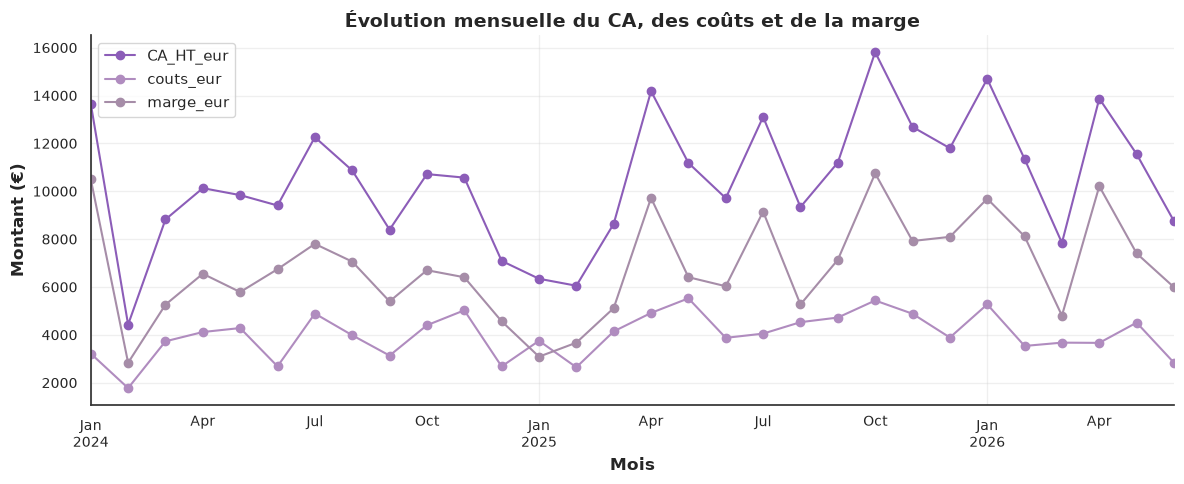

In [25]:
# Evolution temporelles du CA, coûts et marge

df_data['mois'] = df_data['date'].dt.to_period('M')
indicateurs_mensuels = df_data.groupby('mois')[
    ['CA_HT_eur', 'couts_eur', 'marge_eur']
].sum()

indicateurs_mensuels.plot(figsize=(12, 5), marker='o')

plt.title("Évolution mensuelle du CA, des coûts et de la marge")
plt.xlabel("Mois")
plt.ylabel("Montant (€)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
df_data['annee'] = df_data['date'].dt.year

bilan_annuel = df_data.groupby('annee')[
    ['CA_HT_eur', 'couts_eur', 'marge_eur']
].sum()

bilan_annuel

,CA_HT_eur,couts_eur,marge_eur
annee,,,
2024,116168.41,43906.43,75606.77
2025,130047.12,52349.43,82341.78
2026,68052.33,23486.47,46202.55


In [27]:
rentabilite_prestations = df_data.groupby('prestation').agg(
    nombre_interventions=('prestation', 'size'),
    CA_moyen=('CA_HT_eur', 'mean'),
    marge_moyenne=('marge_eur', 'mean'),
    heures_moyennes=('heures_travaillees', 'mean')
)

rentabilite_prestations['marge_horaire'] = (
    df_data.groupby('prestation')['marge_eur'].sum()
    / df_data.groupby('prestation')['heures_travaillees'].sum()
)

rentabilite_prestations.sort_values('marge_horaire', ascending=False)

,nombre_interventions,CA_moyen,marge_moyenne,heures_moyennes,marge_horaire
prestation,,,,,
Plantation,96,665.296250,537.676354,4.585833,117.247251
Semis gazon,98,705.984184,559.937551,4.877449,114.801314
Pose gazon,88,660.194091,525.313864,4.988750,105.299697
Devis,51,358.514902,232.892941,4.504314,51.704423
Plan,59,346.743898,208.330339,5.135763,40.564635
Taille de haie,208,182.116298,66.914327,4.869038,13.742822
Entretien jardin,243,169.605309,53.114527,4.714444,11.266338
Apport d'affaires,67,78.797910,6.546716,4.144627,1.579567


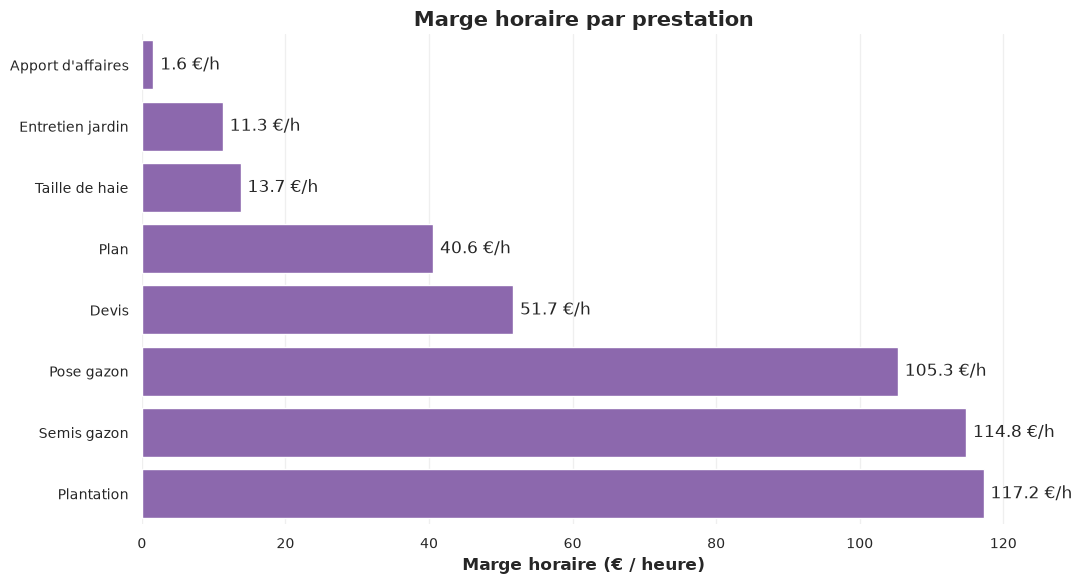

In [28]:

rentabilite = df_data.groupby('prestation').agg(
    nombre_interventions=('prestation', 'size'),
    marge_totale=('marge_eur', 'sum'),
    heures_totales=('heures_travaillees', 'sum')
)

rentabilite['marge_horaire'] = (
    rentabilite['marge_totale'] / rentabilite['heures_totales']
)

rentabilite = rentabilite.sort_values('marge_horaire', ascending=True)
ordre = rentabilite.index.tolist()

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=rentabilite.reset_index(),
    order=ordre,
    x='marge_horaire',
    y='prestation'
)

ax.bar_label(ax.containers[0], fmt='%.1f €/h', padding=5)

plt.title("Marge horaire par prestation", fontsize=15, fontweight='bold')
plt.xlabel("Marge horaire (€ / heure)")
plt.ylabel("")
plt.grid(axis='x', alpha=0.3)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

In [29]:
def analyser_rentabilite(df, categorie):
    resultat = df.groupby(categorie, observed=True).agg(
        interventions=("marge_eur", "size"),
        CA=("CA_HT_eur", "sum"),
        couts=("couts_eur", "sum"),
        marge=("marge_eur", "sum"),
        heures=("heures_travaillees", "sum")
    )

    resultat["taux_marge_pct"] = (
        resultat["marge"] / resultat["CA"] * 100
    )

    resultat["marge_horaire"] = (
        resultat["marge"] / resultat["heures"].replace(0, np.nan)
    )

    return resultat.sort_values("marge_horaire", ascending=False)


for categorie in ["prestation", "client", "commune", "canal_acquisition"]:
    print(f"\n--- Rentabilité par {categorie} ---")
    display(analyser_rentabilite(df_data, categorie).round(2))


--- Rentabilité par prestation ---


,interventions,CA,couts,marge,heures,taux_marge_pct,marge_horaire
prestation,,,,,,,
Plantation,96,63868.44,12260.51,51616.93,440.24,80.82,117.25
Semis gazon,98,69186.45,14360.68,54873.88,477.99,79.31,114.80
Pose gazon,88,58097.08,11869.46,46227.62,439.01,79.57,105.30
Devis,51,18284.26,6511.81,11877.54,229.72,64.96,51.70
Plan,59,20457.89,8278.45,12291.49,303.01,60.08,40.56
Taille de haie,208,37880.19,26633.49,13918.18,1012.76,36.74,13.74
Entretien jardin,243,41214.09,31880.34,12906.83,1145.61,31.32,11.27
Apport d'affaires,67,5279.46,7947.59,438.63,277.69,8.31,1.58



--- Rentabilité par client ---


,interventions,CA,couts,marge,heures,taux_marge_pct,marge_horaire
client,,,,,,,
CL-103,1,1445.44,83.52,1361.92,2.47,94.22,551.38
CL-057,1,1302.84,117.47,1185.37,3.12,90.98,379.93
CL-218,3,2248.12,307.33,1940.79,8.05,86.33,241.09
CL-059,3,2259.64,361.00,1898.64,8.34,84.02,227.65
CL-151,3,1739.61,245.92,1493.69,6.80,85.86,219.66
...,...,...,...,...,...,...,...
CL-200,1,0.00,0.00,0.00,7.22,NaN,0.00
CL-230,3,337.38,362.01,0.00,12.63,0.00,0.00
CL-219,1,205.73,240.70,0.00,7.52,0.00,0.00



--- Rentabilité par commune ---


,interventions,CA,couts,marge,heures,taux_marge_pct,marge_horaire
commune,,,,,,,
Linas,23,9231.64,2417.76,7001.84,99.30,75.85,70.51
Palaiseau,43,18785.90,6016.55,13025.99,215.53,69.34,60.44
Longpont-sur-Orge,50,19788.45,6371.24,14034.72,236.61,70.92,59.32
Ballancourt-sur-Essonne,37,13558.50,4455.58,9324.06,160.77,68.77,58.00
Villebon-sur-Yvette,41,15578.57,5266.30,10791.02,188.02,69.27,57.39
Verrières-le-Buisson,32,12479.28,3993.51,8727.87,152.10,69.94,57.38
Mennecy,36,13793.75,4865.36,9375.31,164.15,67.97,57.11
Nozay,34,14204.53,4712.56,9722.99,170.51,68.45,57.02
Igny,32,11943.50,4540.80,7724.61,143.13,64.68,53.97



--- Rentabilité par canal_acquisition ---


,interventions,CA,couts,marge,heures,taux_marge_pct,marge_horaire
canal_acquisition,,,,,,,
Client recurrent,243,86754.58,29941.13,58811.77,1132.13,67.79,51.95
Site web,226,79745.28,30596.77,51703.64,1062.52,64.84,48.66
Recommandation,231,82100.12,32228.91,52592.86,1118.30,64.06,47.03
Bouche-a-oreille,210,65667.88,26975.52,41042.83,1013.08,62.50,40.51


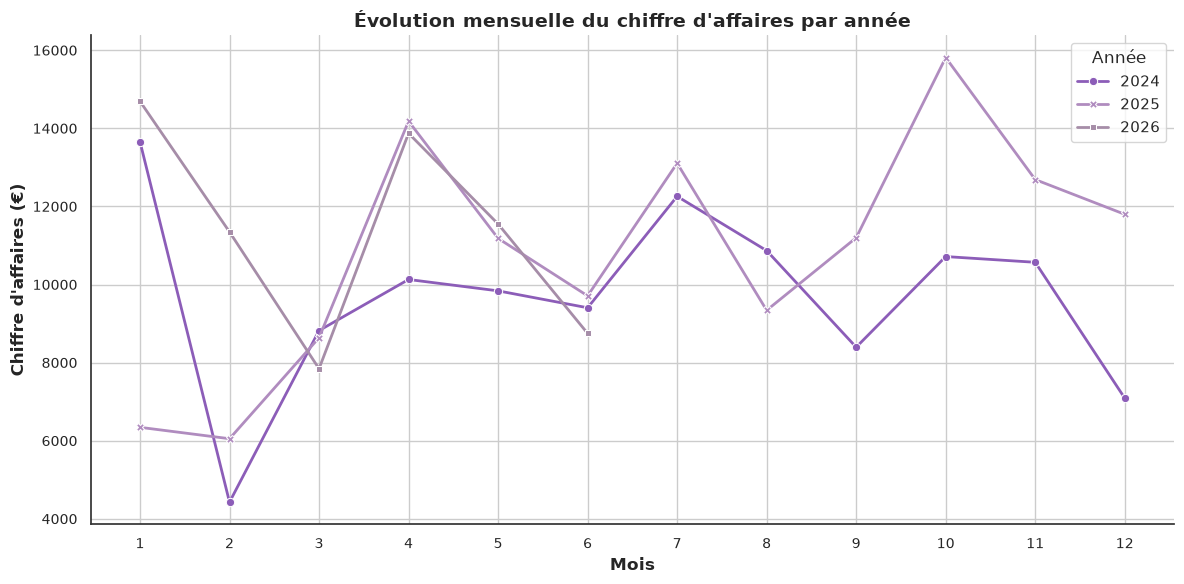

In [30]:
# Agrégation du CA mensuel par année et par mois
CA_saisonnier = df_data.groupby(
    ["annee", df_data["date"].dt.month],
    observed=True
)["CA_HT_eur"].sum().reset_index()

CA_saisonnier.columns = ["annee", "mois", "CA"]

# Tableau croisé pour comparer les années
CA_saisonnier_pivot = CA_saisonnier.pivot(
    index="mois",
    columns="annee",
    values="CA"
)

# Visualisation
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=CA_saisonnier_pivot,
    markers=True,
    dashes=False,
    linewidth=2
)

plt.title("Évolution mensuelle du chiffre d'affaires par année")
plt.xlabel("Mois")
plt.ylabel("Chiffre d'affaires (€)")
plt.xticks(range(1, 13))
plt.legend(title="Année")
plt.tight_layout()
plt.show()

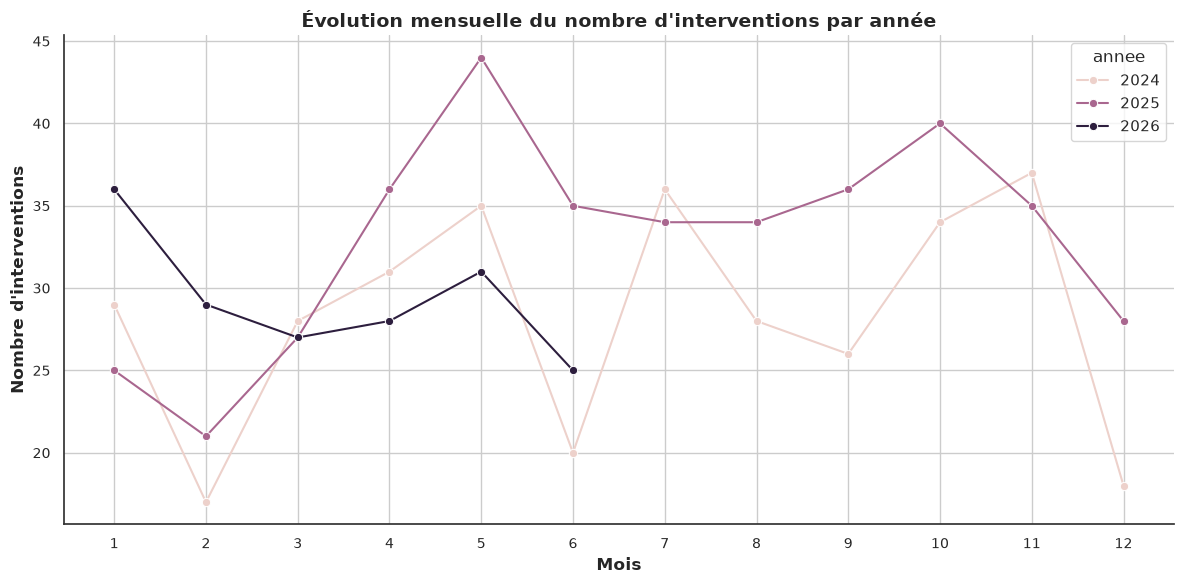

In [31]:
df_data["mois_numero"] = df_data["date"].dt.month

interventions_mensuelles = df_data.groupby(
    ["annee", "mois_numero"],
    observed=True
).size().reset_index(name="nombre_interventions")

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=interventions_mensuelles,
    x="mois_numero",
    y="nombre_interventions",
    hue="annee",
    marker="o"
)

plt.title("Évolution mensuelle du nombre d'interventions par année")
plt.xlabel("Mois")
plt.ylabel("Nombre d'interventions")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

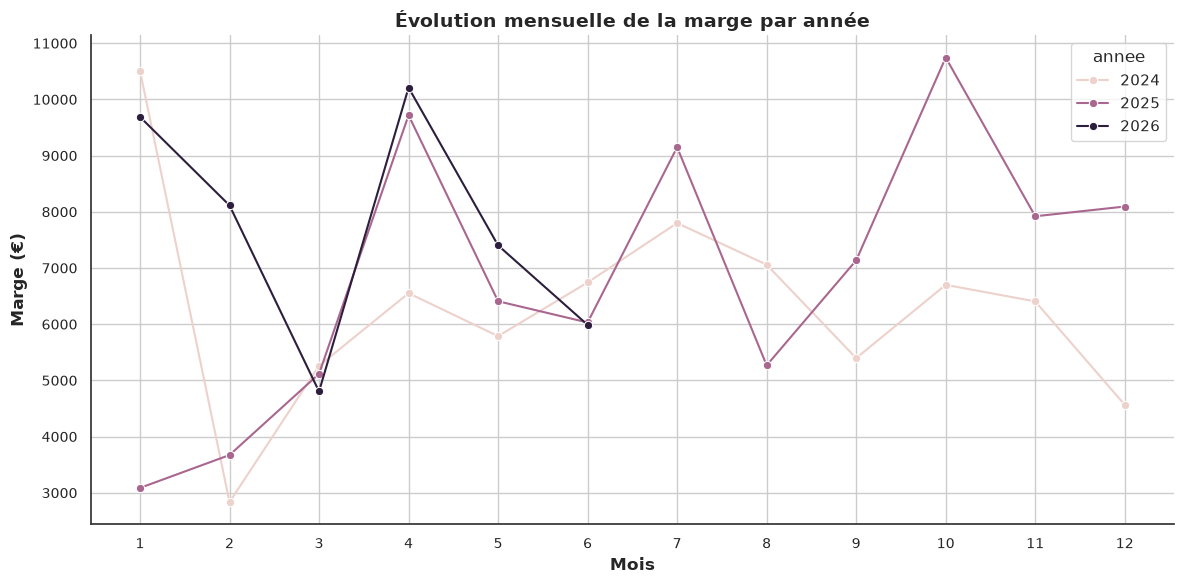

In [32]:
# Agrégation de la marge mensuelle par année
marge_mensuelle = df_data.groupby(
    ["annee", "mois_numero"],
    observed=True
)["marge_eur"].sum().reset_index()

# Visualisation
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=marge_mensuelle,
    x="mois_numero",
    y="marge_eur",
    hue="annee",
    marker="o"
)

plt.title("Évolution mensuelle de la marge par année")
plt.xlabel("Mois")
plt.ylabel("Marge (€)")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

## 1. Synthèse des performances

L'analyse met en évidence des écarts importants de rentabilité entre les prestations.

### Prestations les plus rentables

- **Plantation : 117,25 €/h**
- **Semis gazon : 114,80 €/h**
- **Pose gazon : 105,30 €/h**

À l'inverse, l'**Entretien jardin (11,27 €/h)** et la **Taille de haie (13,74 €/h)** présentent une rentabilité horaire nettement plus faible.

L'activité présente également une **saisonnalité marquée**, avec des pics d'interventions en **octobre, mars, janvier et juillet**.

Enfin, les **clients récurrents** constituent le canal d'acquisition le plus performant, avec une marge horaire de **51,95 €/h**.

---

## 2. Recommandations opérationnelles

- **Développer les prestations rentables :** privilégier commercialement la plantation et les travaux de création de gazon.

- **Améliorer la rentabilité de l'entretien :** réévaluer les tarifs et optimiser les temps d'intervention.

- **Anticiper la saisonnalité :** adapter la planification aux périodes de forte activité.

- **Renforcer la fidélisation :** développer les prestations récurrentes et encourager les recommandations clients.

- **Optimiser les déplacements :** regrouper les interventions par secteur géographique afin de limiter les coûts.

---

## 3. Objectif global

**Améliorer la marge horaire, optimiser l'organisation du travail et privilégier les activités offrant le meilleur potentiel de rentabilité.**


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 5 - Inférence statistique et tests d'hypothèses</h2>
</div>

In [33]:
# Calcul de la marge horaire par intervention
marges_horaires = (
    df_data["marge_eur"] / df_data["heures_travaillees"].replace(0, np.nan)
).replace([np.inf, -np.inf], np.nan).dropna()

# Estimation par bootstrap
resultat = bootstrap(
    (marges_horaires.to_numpy(),),
    np.mean,
    n_resamples=5000,
    confidence_level=0.95,
    method="BCa",
    rng=np.random.default_rng(42)
)

# Résultats
print(f"Marge horaire moyenne : {marges_horaires.mean():.2f} €/h")
print(
    f"Intervalle de confiance à 95 % : "
    f"[{resultat.confidence_interval.low:.2f} ; "
    f"{resultat.confidence_interval.high:.2f}] €/h"
)

Marge horaire moyenne : 60.37 €/h
Intervalle de confiance à 95 % : [54.32 ; 67.67] €/h


In [34]:
# H0 : les distributions de marge sont identiques entre les prestations.
# H1 : au moins une prestation présente une distribution différente.

groupes = [
    groupe["marge_eur"].dropna().to_numpy()
    for _, groupe in df_data.groupby("prestation", observed=True)
    if len(groupe["marge_eur"].dropna()) >= 10
]

stat, p_value = kruskal(*groupes)

print(f"Statistique H : {stat:.3f}")
print(f"p-value : {p_value:.5f}")

if p_value < 0.05:
    print("Conclusion : différence statistiquement significative entre au moins deux prestations.")
else:
    print("Conclusion : aucune différence statistiquement significative détectée.")

Statistique H : 306.163
p-value : 0.00000
Conclusion : différence statistiquement significative entre au moins deux prestations.


In [35]:
# Comparaison des distributions de marge entre deux canaux d'acquisition.

groupe_a = df_data.loc[
    df_data["canal_acquisition"] == "Site web", "marge_eur"
].dropna()

groupe_b = df_data.loc[
    df_data["canal_acquisition"] == "Bouche-a-oreille", "marge_eur"
].dropna()

stat, p_value = mannwhitneyu(
    groupe_a, groupe_b, alternative="two-sided"
)

print(f"Statistique U : {stat:.2f}")
print(f"p-value : {p_value:.4f}")

if p_value < 0.05:
    print("Différence statistiquement significative entre les deux canaux.")
else:
    print("Aucune différence statistiquement significative détectée.")

Statistique U : 24767.50
p-value : 0.4150
Aucune différence statistiquement significative détectée.


In [36]:
# Mesure les corrélations entre les principales variables économiques.

variables = [
    "heures_travaillees",
    "couts_eur",
    "CA_HT_eur",
    "marge_eur"
]

for i, var1 in enumerate(variables):
    for var2 in variables[i + 1:]:
        rho, p_value = spearmanr(
            df_data[var1], df_data[var2], nan_policy="omit"
        )
        print(f"{var1} / {var2}: rho={rho:.3f}, p={p_value:.4g}")

heures_travaillees / couts_eur: rho=0.617, p=1.545e-96
heures_travaillees / CA_HT_eur: rho=0.042, p=0.2101
heures_travaillees / marge_eur: rho=-0.131, p=7.753e-05
couts_eur / CA_HT_eur: rho=0.516, p=3.549e-63
couts_eur / marge_eur: rho=0.276, p=2.294e-17
CA_HT_eur / marge_eur: rho=0.951, p=0


In [37]:
# Pourcentage d'augmentation tarifaire simulé afin d'estimer son impact sur la marge totale.
# Ici, une hausse de 5 % est appliquée au chiffre d'affaires, à coûts et volumes constants.

hausse_tarif_pct = 5

df_data["CA_simule"] = (
    df_data["CA_HT_eur"] * (1 + hausse_tarif_pct / 100)
)

df_data["marge_simulee"] = (
    df_data["CA_simule"] - df_data["couts_eur"]
)

print(f"Marge actuelle : {df_data['marge_eur'].sum():.2f} €")
print(f"Marge simulée : {df_data['marge_simulee'].sum():.2f} €")
print(
    "Gain potentiel : "
    f"{df_data['marge_simulee'].sum() - df_data['marge_eur'].sum():.2f} €"
)

Marge actuelle : 204151.10 €
Marge simulée : 210238.92 €
Gain potentiel : 6087.82 €


In [38]:
# Comparaisons deux à deux des prestations avec Mann-Whitney
# Correction de Holm pour tenir compte des comparaisons multiples.
# Permet d'identifier les différences statistiquement significatives.
groupes = {
    nom: groupe["marge_eur"].dropna()
    for nom, groupe in df_data.groupby("prestation", observed=True)
    if len(groupe) >= 10
}

comparaisons = []

for a, b in combinations(groupes, 2):
    p = mannwhitneyu(groupes[a], groupes[b]).pvalue
    comparaisons.append([a, b, p])

resultats = pd.DataFrame(
    comparaisons,
    columns=["Prestation A", "Prestation B", "p-value"]
)

resultats["p-value corrigée"] = multipletests(
    resultats["p-value"], method="holm"
)[1]

display(resultats.round(4))

,Prestation A,Prestation B,p-value,p-value corrigée
0,Apport d'affaires,Devis,0.0000,0.0000
1,Apport d'affaires,Entretien jardin,0.0000,0.0000
2,Apport d'affaires,Plan,0.0000,0.0000
3,Apport d'affaires,Plantation,0.0000,0.0000
4,Apport d'affaires,Pose gazon,0.0000,0.0000
5,Apport d'affaires,Semis gazon,0.0000,0.0000
6,Apport d'affaires,Taille de haie,0.0000,0.0000
7,Devis,Entretien jardin,0.0000,0.0000
8,Devis,Plan,0.5237,1.0000
9,Devis,Plantation,0.0003,0.0018


### Limites de l'inférence statistique

- Les observations peuvent ne pas être indépendantes, plusieurs interventions pouvant concerner un même client.
- Les tests statistiques identifient des associations et des différences, mais ne démontrent pas de causalité.
- Les résultats doivent être interprétés en tenant compte de la taille et de la représentativité de l'échantillon.

## Conclusion de l'inférence statistique

Les analyses statistiques mettent en évidence plusieurs résultats intéressants.

- **Rentabilité horaire :** la marge horaire moyenne est estimée à 60,37 €/h, avec un intervalle de confiance à 95 % compris entre 54,32 et 67,67 €/h.

- **Différences entre prestations :** le test de Kruskal-Wallis confirme des différences statistiquement significatives entre les prestations (p < 0,001). Les comparaisons post-hoc montrent notamment que Plantation, Pose gazon et Semis gazon présentent des profils de marge différents de plusieurs autres prestations.

- **Canaux d'acquisition :** aucune différence statistiquement significative n'est détectée entre le Site web et le Bouche-à-oreille (p = 0,415).

- **Relations économiques :** le chiffre d'affaires présente une très forte corrélation positive avec la marge (ρ = 0,951). Les heures travaillées sont également positivement corrélées aux coûts (ρ = 0,617).

Ces résultats confirment l'existence de différences de rentabilité entre les prestations et soulignent l'intérêt d'adapter la stratégie commerciale aux activités les plus performantes.


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Exportation des données et conclusions</h2>
</div>

In [39]:
# Exportation csv

data_power_bi = df_data.to_csv("df_data_power_bi.csv", index = False, encoding="utf-8-sig", sep = ";")


# CONCLUSION GÉNÉRALE

---

## 1. Bilan de l'analyse

Cette étude a permis d'analyser les performances économiques et commerciales d'une entreprise de jardinage en Île-de-France, à partir d'un jeu de données d'environ 900 interventions.

Les résultats mettent en évidence plusieurs enseignements :

- **Rentabilité :** les prestations de Plantation, Semis gazon et Pose gazon présentent les meilleures marges horaires, dépassant les 100 €/h.
- **Saisonnalité :** l'activité connaît des pics en octobre, mars, janvier et juillet, ce qui souligne l'importance d'une planification adaptée.
- **Clientèle :** les clients récurrents constituent le canal d'acquisition le plus performant en matière de marge horaire.
- **Performance économique :** les différences de rentabilité entre prestations sont statistiquement significatives.
- **Optimisation :** une simulation d'augmentation tarifaire de 5 % fait apparaître un gain potentiel de marge de 6 087,82 €.

## 2. Recommandations stratégiques

Au regard des résultats obtenus, plusieurs axes d'amélioration peuvent être envisagés :

- **Développer les prestations à forte rentabilité**, notamment la plantation et la création de gazon.
- **Réévaluer la tarification des prestations d'entretien**, dont les marges horaires sont nettement plus faibles.
- **Anticiper les périodes de forte activité** afin d'optimiser la disponibilité et la répartition du travail.
- **Renforcer la fidélisation client** et développer les canaux d'acquisition les plus performants.
- **Améliorer le suivi des coûts et des temps d'intervention** pour identifier les sources de perte de rentabilité.

## 3. Limites de l'analyse

Les résultats doivent être interprétés en tenant compte de certaines limites :

- Le jeu de données reste relativement limité et couvre une période d'environ trois ans.
- Les résultats statistiques dépendent notamment de l'indépendance des observations.
- Les simulations tarifaires reposent sur des hypothèses simplificatrices et ne prennent pas en compte une éventuelle évolution de la demande.
- Les résultats historiques ne garantissent pas les performances futures.

## 4. Conclusion finale

Cette analyse démontre l'intérêt de l'exploitation des données pour piloter la performance d'une entreprise de jardinage.

Elle permet de dépasser le simple suivi du chiffre d'affaires pour identifier les prestations les plus rentables, comprendre les variations d'activité et dégager des pistes concrètes d'optimisation économique.

**L'enjeu principal est désormais de transformer ces observations en décisions opérationnelles afin d'améliorer durablement la rentabilité et l'organisation de l'entreprise.**
